In [1]:
import os
import json
import time
import random
import warnings
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import (
    pack_padded_sequence,
    pad_packed_sequence
)
from torchvision import models, transforms

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: A GPU is strongly recommended for this experiment.")

PyTorch: 2.11.0+cu128
Device: cuda
GPU: Tesla T4


In [2]:
DATASET_ROOT = Path("/kaggle/input")

csv_candidates = list(DATASET_ROOT.rglob("FileList.csv"))
video_dirs = [
    p for p in DATASET_ROOT.rglob("Videos")
    if p.is_dir()
]

print("Metadata files:")
for p in csv_candidates[:10]:
    print(p)

print("\nVideo directories:")
for p in video_dirs[:10]:
    print(p)

if not csv_candidates:
    raise FileNotFoundError(
        "FileList.csv not found. Attach EchoNet-Dynamic under Add Input."
    )

if not video_dirs:
    raise FileNotFoundError(
        "Videos directory not found. Check your Kaggle dataset structure."
    )

# If more than one copy exists, verify these paths before continuing.
CSV_PATH = csv_candidates[0]
VIDEO_DIR = video_dirs[0]

print("\nSelected metadata:", CSV_PATH)
print("Selected videos:", VIDEO_DIR)

Metadata files:
/kaggle/input/datasets/sahilsagramani/echonet-dynamic/EchoNet-Dynamic/FileList.csv

Video directories:
/kaggle/input/datasets/sahilsagramani/echonet-dynamic/EchoNet-Dynamic/Videos

Selected metadata: /kaggle/input/datasets/sahilsagramani/echonet-dynamic/EchoNet-Dynamic/FileList.csv
Selected videos: /kaggle/input/datasets/sahilsagramani/echonet-dynamic/EchoNet-Dynamic/Videos


In [3]:
df = pd.read_csv(CSV_PATH)
df.columns = [str(c).strip() for c in df.columns]

column_lookup = {c.lower(): c for c in df.columns}

required = ["filename", "ef", "split"]
missing = [c for c in required if c not in column_lookup]

if missing:
    raise ValueError(
        f"Missing required columns: {missing}. "
        f"Available columns: {df.columns.tolist()}"
    )

df = df.rename(columns={
    column_lookup["filename"]: "FileName",
    column_lookup["ef"]: "EF",
    column_lookup["split"]: "Split"
})

df["FileName"] = df["FileName"].astype(str).str.strip()
df["EF"] = pd.to_numeric(df["EF"], errors="coerce")
df["Split"] = df["Split"].astype(str).str.strip().str.upper()

df = df.dropna(subset=["FileName", "EF", "Split"]).copy()
df = df[df["EF"].between(0, 100)].copy()
df = df[df["Split"].isin(["TRAIN", "VAL", "TEST"])].copy()
df = df.drop_duplicates(subset=["FileName"]).copy()

print("Metadata records:", len(df))
print("\nOfficial splits:")
display(df["Split"].value_counts().to_frame("Videos"))

print("\nEF summary:")
display(df["EF"].describe().to_frame())

display(df.head())

Metadata records: 10030

Official splits:


,Videos
Split,
TRAIN,7465
VAL,1288
TEST,1277



EF summary:


,EF
count,10030.000000
mean,55.748248
std,12.371483
min,6.907258
25%,51.601387
50%,59.209109
75%,63.958740
max,96.967237


,FileName,EF,ESV,EDV,FrameHeight,FrameWidth,FPS,NumberOfFrames,Split
0,0X100009310A3BD7FC,78.498406,14.881368,69.210534,112,112,50,174,VAL
1,0X1002E8FBACD08477,59.101988,40.383876,98.742884,112,112,50,215,TRAIN
2,0X1005D03EED19C65B,62.363798,14.267784,37.909734,112,112,50,104,TRAIN
3,0X10075961BC11C88E,54.545097,33.143084,72.914210,112,112,55,122,TRAIN
4,0X10094BA0A028EAC3,24.887742,127.581945,169.855024,112,112,52,207,VAL


In [4]:
VIDEO_EXTENSIONS = {".avi", ".mp4", ".mov", ".mkv"}

video_lookup = {}

for path in VIDEO_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in VIDEO_EXTENSIONS:
        video_lookup[path.name.lower()] = str(path)
        video_lookup[path.stem.lower()] = str(path)

def match_video(filename):
    name = Path(filename).name.lower()

    if name in video_lookup:
        return video_lookup[name]

    stem = Path(filename).stem.lower()

    if stem in video_lookup:
        return video_lookup[stem]

    return None

df["VideoPath"] = df["FileName"].apply(match_video)

missing = df["VideoPath"].isna()

print("Videos matched:", int((~missing).sum()))
print("Videos missing:", int(missing.sum()))

if missing.any():
    display(df.loc[missing, ["FileName", "EF", "Split"]].head(20))

    raise FileNotFoundError(
        "Some metadata records could not be matched to videos. "
        "Check the selected VIDEO_DIR before proceeding."
    )

train_df = df[df["Split"] == "TRAIN"].reset_index(drop=True)
val_df = df[df["Split"] == "VAL"].reset_index(drop=True)
test_df = df[df["Split"] == "TEST"].reset_index(drop=True)

print("Train videos:", len(train_df))
print("Validation videos:", len(val_df))
print("Test videos:", len(test_df))

Videos matched: 10030
Videos missing: 0
Train videos: 7465
Validation videos: 1288
Test videos: 1277


In [5]:
IMAGE_SIZE = 112

# Number of frames passed through the CNN at once.
# This is a processing batch size, NOT frame sampling.
CNN_FRAME_BATCH_SIZE = 32

# Batch size counts videos/groups, not individual frames.
VIDEO_BATCH_SIZE = 8

NUM_WORKERS = 2
EPOCHS = 20
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 5

OUTPUT_DIR = Path("/kaggle/working/EchoNet_AllFrames_Experiment")
FEATURE_DIR = OUTPUT_DIR / "video_feature_clusters"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FEATURE_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

df.to_csv(OUTPUT_DIR / "cleaned_video_manifest.csv", index=False)

print("Output directory:", OUTPUT_DIR)
print("Feature cache:", FEATURE_DIR)
print("Image size:", IMAGE_SIZE)
print("CNN processing batch:", CNN_FRAME_BATCH_SIZE)
print("Videos per training batch:", VIDEO_BATCH_SIZE)

Output directory: /kaggle/working/EchoNet_AllFrames_Experiment
Feature cache: /kaggle/working/EchoNet_AllFrames_Experiment/video_feature_clusters
Image size: 112
CNN processing batch: 32
Videos per training batch: 8


In [6]:
try:
    weights = models.MobileNet_V3_Small_Weights.DEFAULT
    mobilenet = models.mobilenet_v3_small(weights=weights)
    print("ImageNet pretrained MobileNetV3-Small loaded.")
except Exception as exc:
    raise RuntimeError(
        "Could not load ImageNet pretrained weights. "
        "Enable Internet in Kaggle settings or attach the weights. "
        "Do not silently substitute random weights if you want a "
        "fair comparison with the previous experiment."
    ) from exc

feature_dim = mobilenet.classifier[0].in_features

cnn = nn.Sequential(
    mobilenet.features,
    mobilenet.avgpool,
    nn.Flatten(start_dim=1)
).to(DEVICE)

# Freeze CNN because we cache its features before temporal training.
cnn.eval()
for parameter in cnn.parameters():
    parameter.requires_grad = False

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

frame_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

print("CNN feature dimension:", feature_dim)
print("CNN frozen:", not any(p.requires_grad for p in cnn.parameters()))

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 129MB/s]


ImageNet pretrained MobileNetV3-Small loaded.
CNN feature dimension: 576
CNN frozen: True


In [7]:
def extract_all_frame_features(video_path):
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise RuntimeError(f"Cannot open video: {video_path}")

    feature_chunks = []
    frame_tensors = []
    decoded_frames = 0

    try:
        while True:
            ok, frame = cap.read()

            if not ok:
                break

            if frame is None:
                continue

            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frame_tensor = frame_transform(frame)
            frame_tensors.append(frame_tensor)
            decoded_frames += 1

            # Process frames in small batches to limit GPU memory.
            if len(frame_tensors) >= CNN_FRAME_BATCH_SIZE:
                batch_tensor = torch.stack(frame_tensors).to(DEVICE)

                with torch.no_grad():
                    features = cnn(batch_tensor)

                feature_chunks.append(
                    features.cpu().to(torch.float16)
                )
                frame_tensors.clear()

        # Process remaining frames.
        if frame_tensors:
            batch_tensor = torch.stack(frame_tensors).to(DEVICE)

            with torch.no_grad():
                features = cnn(batch_tensor)

            feature_chunks.append(
                features.cpu().to(torch.float16)
            )

    finally:
        cap.release()

    if decoded_frames == 0 or not feature_chunks:
        raise RuntimeError(f"No readable frames found in: {video_path}")

    all_features = torch.cat(feature_chunks, dim=0)

    assert all_features.shape[0] == decoded_frames

    return all_features, decoded_frames


def cache_video_clusters(metadata, split_name):
    rows = []
    total_frames = 0

    for index, row in metadata.iterrows():
        video_path = row["VideoPath"]
        file_name = row["FileName"]
        ef = float(row["EF"])

        # Unique cache name even if two records share a similar filename.
        cache_name = f"{split_name}_{index:05d}_{Path(file_name).stem}.pt"
        cache_path = FEATURE_DIR / cache_name

        if cache_path.exists():
            saved = torch.load(
                cache_path,
                map_location="cpu",
                weights_only=False
            )
            features = saved["features"]
            num_frames = int(saved["num_frames"])
        else:
            features, num_frames = extract_all_frame_features(video_path)

            torch.save({
                "features": features,
                "num_frames": num_frames
            }, cache_path)

        if features.shape[0] != num_frames:
            raise ValueError(f"Frame count mismatch for {file_name}")

        rows.append({
            "FileName": file_name,
            "VideoPath": video_path,
            "EF": ef,
            "Split": split_name,
            "NumFrames": num_frames,
            "FeaturePath": str(cache_path)
        })

        total_frames += num_frames

        if (index + 1) % 100 == 0 or index + 1 == len(metadata):
            print(
                f"{split_name}: {index + 1}/{len(metadata)} videos | "
                f"frames processed so far: {total_frames:,}"
            )

    return pd.DataFrame(rows)


# Build one cluster for each video in each official split.
train_clusters = cache_video_clusters(train_df, "TRAIN")
val_clusters = cache_video_clusters(val_df, "VAL")
test_clusters = cache_video_clusters(test_df, "TEST")

cluster_manifest = pd.concat(
    [train_clusters, val_clusters, test_clusters],
    ignore_index=True
)

cluster_manifest.to_csv(
    OUTPUT_DIR / "all_frame_cluster_manifest.csv",
    index=False
)

print("\nTotal video clusters:", len(cluster_manifest))
print("Total decoded frames:", int(cluster_manifest["NumFrames"].sum()))

display(
    cluster_manifest.groupby("Split")["NumFrames"]
    .agg(["count", "sum", "mean", "min", "max"])
)

TRAIN: 100/7465 videos | frames processed so far: 17,105
TRAIN: 200/7465 videos | frames processed so far: 34,345
TRAIN: 300/7465 videos | frames processed so far: 52,068
TRAIN: 400/7465 videos | frames processed so far: 69,200
TRAIN: 500/7465 videos | frames processed so far: 85,519
TRAIN: 600/7465 videos | frames processed so far: 103,126
TRAIN: 700/7465 videos | frames processed so far: 121,047
TRAIN: 800/7465 videos | frames processed so far: 138,705
TRAIN: 900/7465 videos | frames processed so far: 156,216
TRAIN: 1000/7465 videos | frames processed so far: 173,696
TRAIN: 1100/7465 videos | frames processed so far: 191,367
TRAIN: 1200/7465 videos | frames processed so far: 208,500
TRAIN: 1300/7465 videos | frames processed so far: 226,165
TRAIN: 1400/7465 videos | frames processed so far: 243,182
TRAIN: 1500/7465 videos | frames processed so far: 260,364
TRAIN: 1600/7465 videos | frames processed so far: 278,341
TRAIN: 1700/7465 videos | frames processed so far: 295,809
TRAIN: 1800

,count,sum,mean,min,max
Split,,,,,
TEST,1277,226460,177.337510,36,1002
TRAIN,7465,1315340,176.200938,28,1002
VAL,1288,228836,177.667702,37,690


In [ ]:
# CHUNK 1: SAVE ALL FEATURE CLUSTERS FOR LATER USE

import os
import json
import shutil
import zipfile
from pathlib import Path

# Directory containing all saved video feature clusters
FEATURE_DIR = Path(FEATURE_DIR)
OUTPUT_DIR = Path(OUTPUT_DIR)

# Save the cluster manifest
cluster_manifest_path = OUTPUT_DIR / "all_frame_cluster_manifest.csv"
cluster_manifest.to_csv(cluster_manifest_path, index=False)

# Save essential experiment metadata
checkpoint_metadata = {
    "dataset": "EchoNet-Dynamic",
    "feature_extractor": "ImageNet-pretrained MobileNetV3-Small",
    "feature_dim": int(feature_dim),
    "image_size": int(IMAGE_SIZE),
    "frame_sampling": "All successfully decoded frames; no sampling",
    "label": "One EF label per video cluster",
    "train_videos": int(len(train_clusters)),
    "validation_videos": int(len(val_clusters)),
    "test_videos": int(len(test_clusters)),
    "total_videos": int(len(cluster_manifest)),
    "total_frames": int(cluster_manifest["NumFrames"].sum())
}

metadata_path = OUTPUT_DIR / "cluster_experiment_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(checkpoint_metadata, f, indent=2)

# Check that every cluster file exists
missing_files = [
    path for path in cluster_manifest["FeaturePath"]
    if not Path(path).exists()
]

if missing_files:
    raise FileNotFoundError(
        f"{len(missing_files)} feature files are missing. "
        "Do not create the backup until these are resolved."
    )

# Create a portable package containing clusters and manifest.
# Store relative paths so the package can be relocated.
BACKUP_DIR = Path("/kaggle/working/EchoNet_AllFrames_Backup")
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

BACKUP_FEATURE_DIR = BACKUP_DIR / "video_feature_clusters"
BACKUP_FEATURE_DIR.mkdir(parents=True, exist_ok=True)

print("Copying feature clusters into the backup folder...")

for i, source in enumerate(cluster_manifest["FeaturePath"], start=1):
    source = Path(source)
    destination = BACKUP_FEATURE_DIR / source.name

    if not destination.exists():
        shutil.copy2(source, destination)

    if i % 500 == 0 or i == len(cluster_manifest):
        print(f"Copied {i}/{len(cluster_manifest)} clusters")

# Write a portable manifest with paths relative to the ZIP root
portable_manifest = cluster_manifest.copy()
portable_manifest["FeaturePath"] = portable_manifest["FeaturePath"].apply(
    lambda p: str(Path("video_feature_clusters") / Path(p).name)
)

portable_manifest.to_csv(
    BACKUP_DIR / "all_frame_cluster_manifest.csv",
    index=False
)

with open(BACKUP_DIR / "cluster_experiment_metadata.json", "w") as f:
    json.dump(checkpoint_metadata, f, indent=2)

# Create a ZIP package
ZIP_PATH = Path("/kaggle/working/EchoNet_AllFrames_Backup.zip")

print("Creating ZIP archive. This may take some time...")

with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_STORED
) as zf:
    for file_path in BACKUP_DIR.rglob("*"):
        if file_path.is_file():
            zf.write(
                file_path,
                arcname=str(file_path.relative_to(BACKUP_DIR))
            )

print("\nBackup complete!")
print("ZIP path:", ZIP_PATH)
print("ZIP size (GB):", round(ZIP_PATH.stat().st_size / (1024**3), 2))
print("Total videos:", checkpoint_metadata["total_videos"])
print("Total decoded frames:", checkpoint_metadata["total_frames"])

In [15]:
assert len(train_clusters) == len(train_df)
assert len(val_clusters) == len(val_df)
assert len(test_clusters) == len(test_df)

# Inspect several clusters.
for _, row in cluster_manifest.head(5).iterrows():
    saved = torch.load(
        row["FeaturePath"],
        map_location="cpu",
        weights_only=False
    )

    features = saved["features"]

    print(
        row["Split"],
        "| Video:", row["FileName"],
        "| EF label:", row["EF"],
        "| Feature shape:", tuple(features.shape),
        "| Number of frames:", row["NumFrames"]
    )

    assert features.shape[0] == row["NumFrames"]
    assert features.shape[1] == feature_dim

print("\nAll inspected clusters passed the shape checks.")

TRAIN | Video: 0X1002E8FBACD08477 | EF label: 59.10198811 | Feature shape: (215, 576) | Number of frames: 215
TRAIN | Video: 0X1005D03EED19C65B | EF label: 62.36379841 | Feature shape: (104, 576) | Number of frames: 104
TRAIN | Video: 0X10075961BC11C88E | EF label: 54.54509675 | Feature shape: (122, 576) | Number of frames: 122
TRAIN | Video: 0X100E3B8D3280BEC5 | EF label: 36.57373876 | Feature shape: (101, 576) | Number of frames: 101
TRAIN | Video: 0X100E491B3CD58DE2 | EF label: 33.99174499 | Feature shape: (226, 576) | Number of frames: 226

All inspected clusters passed the shape checks.


In [16]:
class EchoClusterDataset(Dataset):
    def __init__(self, manifest):
        self.data = manifest.reset_index(drop=True).copy()

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        saved = torch.load(
            row["FeaturePath"],
            map_location="cpu",
            weights_only=False
        )

        features = saved["features"].float()

        return {
            "features": features,  # [all frames in this video, D]
            "EF": torch.tensor(float(row["EF"]), dtype=torch.float32),
            "FileName": str(row["FileName"]),
            "length": int(features.shape[0])
        }


def collate_clusters(batch):
    lengths = torch.tensor(
        [item["length"] for item in batch],
        dtype=torch.long
    )

    max_length = int(lengths.max())
    feature_dim_local = batch[0]["features"].shape[1]

    padded = torch.zeros(
        len(batch),
        max_length,
        feature_dim_local,
        dtype=torch.float32
    )

    targets = []
    names = []

    for i, item in enumerate(batch):
        n = item["length"]
        padded[i, :n] = item["features"]
        targets.append(item["EF"])
        names.append(item["FileName"])

    return {
        "features": padded,
        "lengths": lengths,
        "EF": torch.stack(targets),
        "FileName": names
    }


train_dataset = EchoClusterDataset(train_clusters)
val_dataset = EchoClusterDataset(val_clusters)
test_dataset = EchoClusterDataset(test_clusters)

train_loader = DataLoader(
    train_dataset,
    batch_size=VIDEO_BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    collate_fn=collate_clusters,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=VIDEO_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    collate_fn=collate_clusters,
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=VIDEO_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    collate_fn=collate_clusters,
    pin_memory=(DEVICE.type == "cuda")
)

batch = next(iter(train_loader))

print("Batch feature shape:", tuple(batch["features"].shape))
print("Video lengths:", batch["lengths"].tolist())
print("One label per video:", batch["EF"].shape)
print("Video IDs:", batch["FileName"])

Batch feature shape: (8, 288, 576)
Video lengths: [166, 185, 129, 197, 288, 255, 171, 152]
One label per video: torch.Size([8])
Video IDs: ['0X12743BE18328C2CB', '0X4CDA2C041B3645A3', '0X1B25F9E969909539', '0X6A878BE2BE37679E', '0X3C0B954729E57D23', '0X2E61656CEDFA0B02', '0X75FCE4E4D09346E8', '0X34A86702D598B94']


In [17]:
class EFClusterModel(nn.Module):
    def __init__(self, temporal="bilstm", hidden_size=128, dropout=0.3):
        super().__init__()

        if temporal not in {"average", "bilstm"}:
            raise ValueError("temporal must be 'average' or 'bilstm'")

        self.temporal = temporal

        if temporal == "bilstm":
            self.temporal_model = nn.LSTM(
                input_size=feature_dim,
                hidden_size=hidden_size,
                num_layers=1,
                batch_first=True,
                bidirectional=True
            )
            head_dim = hidden_size * 2
        else:
            self.temporal_model = None
            head_dim = feature_dim

        self.regressor = nn.Sequential(
            nn.Linear(head_dim, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(128, 1)
        )

    def forward(self, features, lengths):
        # features: [batch of videos, padded frames, feature dimension]
        batch_size, max_length, _ = features.shape

        valid_mask = (
            torch.arange(max_length, device=features.device)[None, :]
            < lengths.to(features.device)[:, None]
        )

        if self.temporal == "bilstm":
            packed = pack_padded_sequence(
                features,
                lengths.cpu(),
                batch_first=True,
                enforce_sorted=False
            )

            packed_output, _ = self.temporal_model(packed)

            sequence_output, _ = pad_packed_sequence(
                packed_output,
                batch_first=True,
                total_length=max_length
            )

            mask = valid_mask.unsqueeze(-1).to(sequence_output.dtype)

            video_features = (
                (sequence_output * mask).sum(dim=1)
                / lengths.to(features.device).unsqueeze(1)
            )
        else:
            mask = valid_mask.unsqueeze(-1).to(features.dtype)

            video_features = (
                (features * mask).sum(dim=1)
                / lengths.to(features.device).unsqueeze(1)
            )

        # One scalar prediction per video.
        return self.regressor(video_features).squeeze(1)


average_model = EFClusterModel("average").to(DEVICE)
bilstm_model = EFClusterModel("bilstm").to(DEVICE)

print("Average model parameters:", sum(
    p.numel() for p in average_model.parameters() if p.requires_grad
))
print("BiLSTM model parameters:", sum(
    p.numel() for p in bilstm_model.parameters() if p.requires_grad
))

Average model parameters: 73985
BiLSTM model parameters: 755969


In [19]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    targets_all = []
    predictions_all = []

    for batch in loader:
        features = batch["features"].to(DEVICE, non_blocking=True)
        lengths = batch["lengths"]
        targets = batch["EF"].to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            predictions = model(features, lengths)
            loss = criterion(predictions, targets)

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

        total_loss += loss.item() * len(targets)

        targets_all.extend(targets.detach().cpu().numpy())
        predictions_all.extend(predictions.detach().cpu().numpy())

    targets_all = np.asarray(targets_all, dtype=np.float64)
    predictions_all = np.asarray(predictions_all, dtype=np.float64)

    return {
        "loss": total_loss / max(len(targets_all), 1),
        "mae": mean_absolute_error(targets_all, predictions_all),
        "rmse": np.sqrt(mean_squared_error(targets_all, predictions_all)),
        "targets": targets_all,
        "predictions": predictions_all
    }


def train_model(temporal, model_name):
    model = EFClusterModel(temporal=temporal).to(DEVICE)

    criterion = nn.SmoothL1Loss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=2
    )

    checkpoint_path = CHECKPOINT_DIR / f"{model_name}_best.pt"
    history = []
    best_val_mae = float("inf")
    epochs_without_improvement = 0

    for epoch in range(1, EPOCHS + 1):
        start_time = time.time()

        train_result = run_epoch(
            model, train_loader, criterion, optimizer
        )

        with torch.no_grad():
            val_result = run_epoch(
                model, val_loader, criterion, optimizer=None
            )

        scheduler.step(val_result["mae"])

        history.append({
            "epoch": epoch,
            "train_loss": train_result["loss"],
            "val_loss": val_result["loss"],
            "train_mae": train_result["mae"],
            "val_mae": val_result["mae"],
            "train_rmse": train_result["rmse"],
            "val_rmse": val_result["rmse"],
            "learning_rate": optimizer.param_groups[0]["lr"]
        })

        print(
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"Train MAE {train_result['mae']:.4f} | "
            f"Val MAE {val_result['mae']:.4f} | "
            f"Val RMSE {val_result['rmse']:.4f} | "
            f"{time.time() - start_time:.1f}s"
        )

        if val_result["mae"] < best_val_mae:
            best_val_mae = val_result["mae"]
            epochs_without_improvement = 0

            torch.save({
                "model_state_dict": model.state_dict(),
                "temporal": temporal,
                "best_val_mae": best_val_mae,
                "feature_dim": feature_dim,
                "image_size": IMAGE_SIZE,
                "seed": SEED
            }, checkpoint_path)
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            print("Early stopping.")
            break

    # Reload the best validation checkpoint.
    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )
    model.load_state_dict(checkpoint["model_state_dict"])

    history_df = pd.DataFrame(history)
    history_df.to_csv(
        OUTPUT_DIR / f"{model_name}_training_history.csv",
        index=False
    )

    return model, history_df, checkpoint_path

In [20]:
average_model, average_history, average_checkpoint = train_model(
    temporal="average",
    model_name="mobilenetv3_allframes_average"
)

print("Best validation MAE:", average_history["val_mae"].min())
print("Checkpoint:", average_checkpoint)

Epoch 01/20 | Train MAE 28.5458 | Val MAE 9.1560 | Val RMSE 12.8260 | 9.3s
Epoch 02/20 | Train MAE 10.1110 | Val MAE 8.8115 | Val RMSE 12.2987 | 9.2s
Epoch 03/20 | Train MAE 9.7340 | Val MAE 8.5883 | Val RMSE 11.9800 | 9.2s
Epoch 04/20 | Train MAE 9.6649 | Val MAE 8.4907 | Val RMSE 11.6843 | 9.3s
Epoch 05/20 | Train MAE 9.4803 | Val MAE 8.4653 | Val RMSE 11.4820 | 9.3s
Epoch 06/20 | Train MAE 9.3832 | Val MAE 8.3650 | Val RMSE 11.3726 | 9.4s
Epoch 07/20 | Train MAE 9.4294 | Val MAE 8.2574 | Val RMSE 11.2780 | 9.2s
Epoch 08/20 | Train MAE 9.3000 | Val MAE 8.1441 | Val RMSE 11.3406 | 9.2s
Epoch 09/20 | Train MAE 9.3533 | Val MAE 8.1035 | Val RMSE 11.3293 | 9.4s
Epoch 10/20 | Train MAE 9.2417 | Val MAE 8.1605 | Val RMSE 11.1353 | 9.4s
Epoch 11/20 | Train MAE 9.2572 | Val MAE 8.1001 | Val RMSE 11.1117 | 9.2s
Epoch 12/20 | Train MAE 9.2626 | Val MAE 8.0982 | Val RMSE 11.0755 | 9.3s
Epoch 13/20 | Train MAE 9.2698 | Val MAE 8.0032 | Val RMSE 11.2159 | 9.3s
Epoch 14/20 | Train MAE 9.2196 | Val

In [21]:
bilstm_model, bilstm_history, bilstm_checkpoint = train_model(
    temporal="bilstm",
    model_name="mobilenetv3_allframes_bilstm"
)

print("Best validation MAE:", bilstm_history["val_mae"].min())
print("Checkpoint:", bilstm_checkpoint)

Epoch 01/20 | Train MAE 25.5462 | Val MAE 8.6543 | Val RMSE 12.4797 | 22.0s
Epoch 02/20 | Train MAE 10.0281 | Val MAE 8.5166 | Val RMSE 11.7109 | 22.2s
Epoch 03/20 | Train MAE 9.6405 | Val MAE 8.0595 | Val RMSE 11.0673 | 22.4s
Epoch 04/20 | Train MAE 9.4283 | Val MAE 7.8021 | Val RMSE 10.6307 | 22.2s
Epoch 05/20 | Train MAE 9.3448 | Val MAE 8.8762 | Val RMSE 11.3596 | 22.2s
Epoch 06/20 | Train MAE 9.2254 | Val MAE 7.8063 | Val RMSE 10.3764 | 22.3s
Epoch 07/20 | Train MAE 9.1426 | Val MAE 7.6358 | Val RMSE 11.0388 | 22.6s
Epoch 08/20 | Train MAE 9.0102 | Val MAE 7.4637 | Val RMSE 10.3840 | 22.1s
Epoch 09/20 | Train MAE 8.9757 | Val MAE 7.6430 | Val RMSE 11.1224 | 23.1s
Epoch 10/20 | Train MAE 8.9199 | Val MAE 7.4208 | Val RMSE 10.1500 | 22.2s
Epoch 11/20 | Train MAE 8.7686 | Val MAE 7.3597 | Val RMSE 10.0028 | 22.0s
Epoch 12/20 | Train MAE 8.6382 | Val MAE 8.5573 | Val RMSE 11.3099 | 22.5s
Epoch 13/20 | Train MAE 8.6942 | Val MAE 7.7195 | Val RMSE 10.5570 | 22.0s
Epoch 14/20 | Train MAE

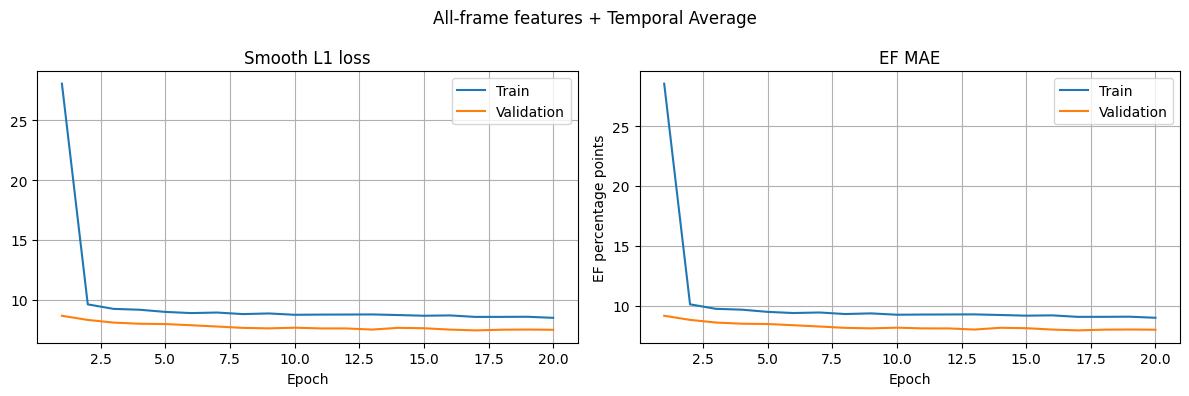

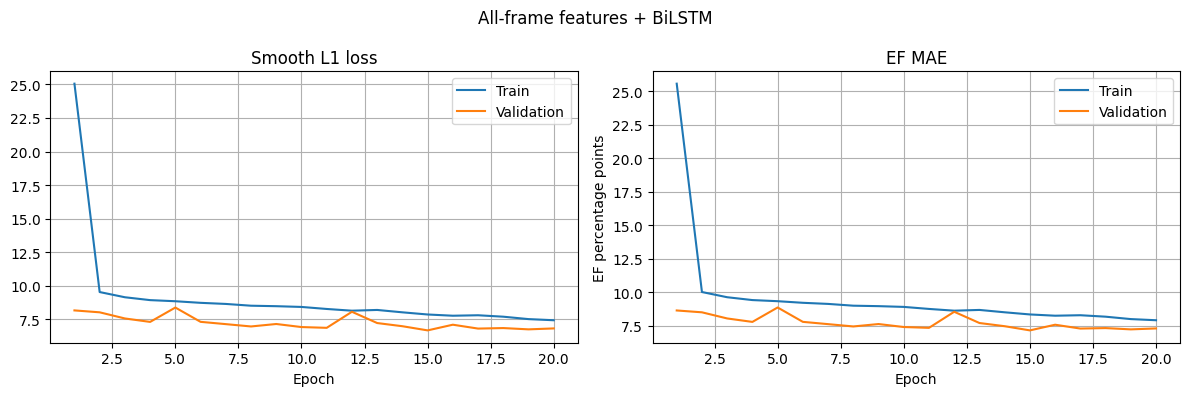

In [22]:
def plot_history(history_df, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train")
    axes[0].plot(history_df["epoch"], history_df["val_loss"], label="Validation")
    axes[0].set_title("Smooth L1 loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(history_df["epoch"], history_df["train_mae"], label="Train")
    axes[1].plot(history_df["epoch"], history_df["val_mae"], label="Validation")
    axes[1].set_title("EF MAE")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("EF percentage points")
    axes[1].legend()
    axes[1].grid(True)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_history(average_history, "All-frame features + Temporal Average")
plot_history(bilstm_history, "All-frame features + BiLSTM")

In [23]:
def calculate_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)

    pearson_r = (
        float(np.corrcoef(y_true, y_pred)[0, 1])
        if len(y_true) > 1
        and np.std(y_true) > 0
        and np.std(y_pred) > 0
        else np.nan
    )

    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "MSE": float(mean_squared_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)),
        "Pearson_r": pearson_r,
        "Within_5_EF_points_percent": float(
            100 * np.mean(np.abs(y_true - y_pred) <= 5)
        )
    }


def evaluate_test_set(model, loader, model_name):
    model.eval()

    y_true = []
    y_pred = []
    names = []
    total_forward_seconds = 0.0

    with torch.no_grad():
        for batch in loader:
            features = batch["features"].to(DEVICE, non_blocking=True)
            lengths = batch["lengths"]

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            start = time.perf_counter()

            predictions = model(features, lengths)

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            total_forward_seconds += time.perf_counter() - start

            y_true.extend(batch["EF"].numpy().tolist())
            y_pred.extend(predictions.cpu().numpy().tolist())
            names.extend(batch["FileName"])

    metrics = calculate_metrics(y_true, y_pred)
    metrics["Model"] = model_name
    metrics["Test_videos"] = len(y_true)
    metrics["Forward_seconds_total"] = total_forward_seconds
    metrics["Forward_ms_per_video"] = (
        1000 * total_forward_seconds / max(len(y_true), 1)
    )

    predictions_df = pd.DataFrame({
        "FileName": names,
        "EF_true": y_true,
        "EF_predicted": y_pred,
        "Absolute_error": np.abs(np.asarray(y_true) - np.asarray(y_pred))
    })

    predictions_df.to_csv(
        OUTPUT_DIR / f"{model_name}_test_predictions.csv",
        index=False
    )

    return metrics, predictions_df


average_metrics, average_predictions = evaluate_test_set(
    average_model, test_loader, "allframes_average"
)

bilstm_metrics, bilstm_predictions = evaluate_test_set(
    bilstm_model, test_loader, "allframes_bilstm"
)

comparison_df = pd.DataFrame([
    average_metrics,
    bilstm_metrics
])

display(comparison_df.round(4))

comparison_df.to_csv(
    OUTPUT_DIR / "test_metrics_comparison.csv",
    index=False
)

,MAE,MSE,RMSE,R2,Pearson_r,Within_5_EF_points_percent,Model,Test_videos,Forward_seconds_total,Forward_ms_per_video
0,8.0906,125.6402,11.2089,0.1594,0.4553,45.4190,allframes_average,1277,0.1680,0.1316
1,7.3941,109.2613,10.4528,0.2690,0.5777,49.0211,allframes_bilstm,1277,1.5579,1.2200


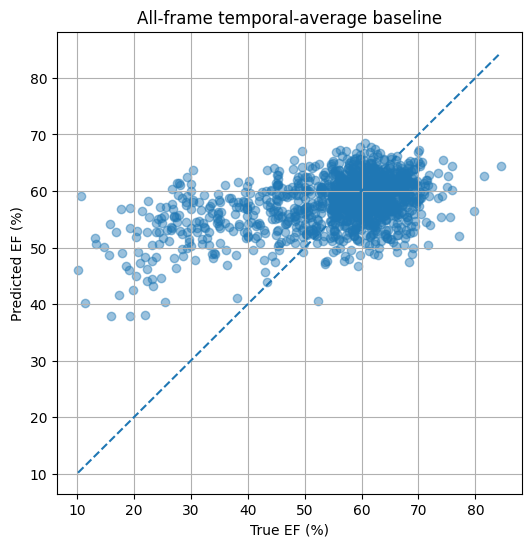

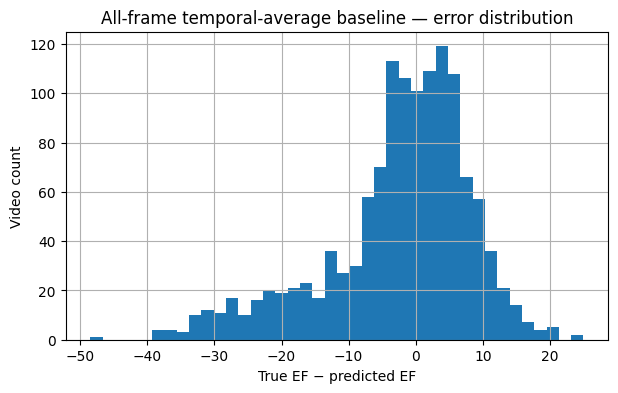

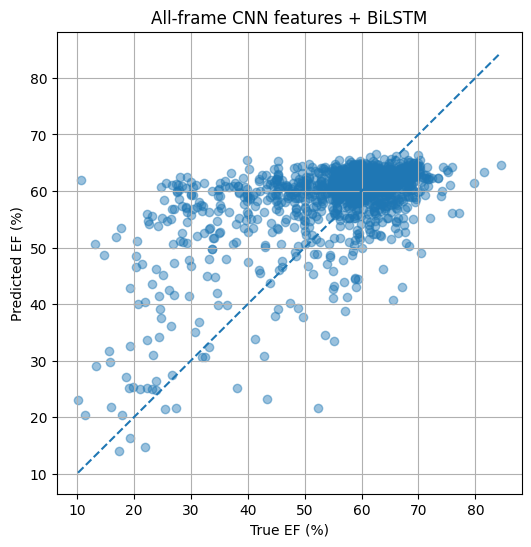

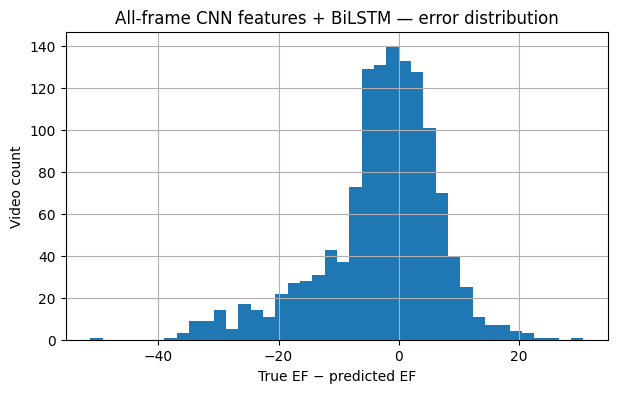

In [24]:
def plot_predictions(predictions_df, title):
    y_true = predictions_df["EF_true"].to_numpy()
    y_pred = predictions_df["EF_predicted"].to_numpy()

    low = min(y_true.min(), y_pred.min())
    high = max(y_true.max(), y_pred.max())

    plt.figure(figsize=(6, 6))
    plt.scatter(y_true, y_pred, alpha=0.45)
    plt.plot([low, high], [low, high], "--")
    plt.xlabel("True EF (%)")
    plt.ylabel("Predicted EF (%)")
    plt.title(title)
    plt.grid(True)
    plt.show()

    errors = y_true - y_pred

    plt.figure(figsize=(7, 4))
    plt.hist(errors, bins=40)
    plt.xlabel("True EF − predicted EF")
    plt.ylabel("Video count")
    plt.title(title + " — error distribution")
    plt.grid(True)
    plt.show()


plot_predictions(
    average_predictions,
    "All-frame temporal-average baseline"
)

plot_predictions(
    bilstm_predictions,
    "All-frame CNN features + BiLSTM"
)

In [25]:
def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


def checkpoint_size_mb(path):
    return os.path.getsize(path) / (1024 ** 2)


efficiency_df = pd.DataFrame([
    {
        "Model": "All-frame temporal average",
        "Trainable_temporal_parameters": count_parameters(average_model),
        "Checkpoint_MB": checkpoint_size_mb(average_checkpoint),
        "Test_MAE": average_metrics["MAE"],
        "Test_RMSE": average_metrics["RMSE"],
        "Forward_ms_per_video": average_metrics["Forward_ms_per_video"]
    },
    {
        "Model": "All-frame BiLSTM",
        "Trainable_temporal_parameters": count_parameters(bilstm_model),
        "Checkpoint_MB": checkpoint_size_mb(bilstm_checkpoint),
        "Test_MAE": bilstm_metrics["MAE"],
        "Test_RMSE": bilstm_metrics["RMSE"],
        "Forward_ms_per_video": bilstm_metrics["Forward_ms_per_video"]
    }
])

display(efficiency_df.round(4))

efficiency_df.to_csv(
    OUTPUT_DIR / "model_efficiency_comparison.csv",
    index=False
)

,Model,Trainable_temporal_parameters,Checkpoint_MB,Test_MAE,Test_RMSE,Forward_ms_per_video
0,All-frame temporal average,73985,0.2852,8.0906,11.2089,0.1316
1,All-frame BiLSTM,755969,2.8877,7.3941,10.4528,1.2200


In [26]:
summary = {
    "dataset": "EchoNet-Dynamic",
    "task": "Video-level EF regression using all decodable frames",
    "frame_sampling": "None; every successfully decoded frame is processed",
    "cluster_definition": "One CNN feature sequence per video",
    "label_definition": "One video-level EF target per cluster",
    "cnn": "ImageNet-pretrained MobileNetV3-Small",
    "cnn_frozen_during_temporal_training": True,
    "temporal_models": ["Average pooling", "BiLSTM"],
    "image_size": IMAGE_SIZE,
    "cnn_frame_batch_size": CNN_FRAME_BATCH_SIZE,
    "video_batch_size": VIDEO_BATCH_SIZE,
    "seed": SEED,
    "train_videos": len(train_clusters),
    "validation_videos": len(val_clusters),
    "test_videos": len(test_clusters),
    "total_decoded_frames": int(cluster_manifest["NumFrames"].sum()),
    "frames_by_split": {
        str(split): int(count)
        for split, count in cluster_manifest.groupby("Split")["NumFrames"].sum().items()
    },
    "best_average_validation_MAE": float(average_history["val_mae"].min()),
    "best_bilstm_validation_MAE": float(bilstm_history["val_mae"].min()),
    "average_pooling_test_metrics": average_metrics,
    "bilstm_test_metrics": bilstm_metrics
}

with open(OUTPUT_DIR / "experiment_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=float)

print(json.dumps(summary, indent=2, default=float))
print("\nExperiment files saved in:", OUTPUT_DIR)

{
  "dataset": "EchoNet-Dynamic",
  "task": "Video-level EF regression using all decodable frames",
  "frame_sampling": "None; every successfully decoded frame is processed",
  "cluster_definition": "One CNN feature sequence per video",
  "label_definition": "One video-level EF target per cluster",
  "cnn": "ImageNet-pretrained MobileNetV3-Small",
  "cnn_frozen_during_temporal_training": true,
  "temporal_models": [
    "Average pooling",
    "BiLSTM"
  ],
  "image_size": 112,
  "cnn_frame_batch_size": 32,
  "video_batch_size": 8,
  "seed": 42,
  "train_videos": 7465,
  "validation_videos": 1288,
  "test_videos": 1277,
  "total_decoded_frames": 1770636,
  "frames_by_split": {
    "TEST": 226460,
    "TRAIN": 1315340,
    "VAL": 228836
  },
  "best_average_validation_MAE": 7.933280320641417,
  "best_bilstm_validation_MAE": 7.170613614668757,
  "average_pooling_test_metrics": {
    "MAE": 8.090630316977027,
    "MSE": 125.64020250486412,
    "RMSE": 11.208934048555381,
    "R2": 0.159387